## Task 1: Basic K-Means Clustering
### Description
In this task, we generate a synthetic dataset and apply the K-Means clustering algorithm to group data points into four clusters. This helps us understand how K-Means identifies centroids and assigns data points to the nearest centroid.

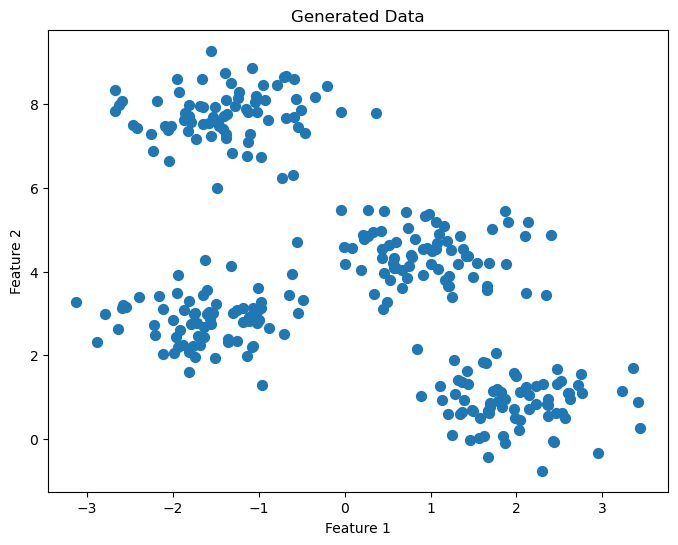

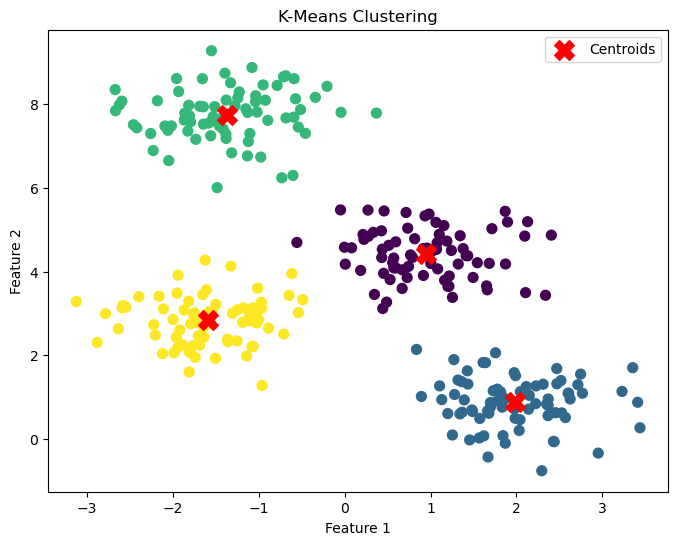

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate synthetic data
X, y = make_blobs(n_samples=300,centers=4,cluster_std=0.60,random_state=0)

# 2. Visualize generated data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Generated Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Apply K-Means clustering
k_means = KMeans(n_clusters=4,init="k-means++",max_iter=300,random_state=0,n_init=10)
y_kmeans = k_means.fit_predict(X)

# 4. Visualize clusters and centroids
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0],X[:, 1],c=y_kmeans,s=50,cmap="viridis")

# Plot centroids
centroids = k_means.cluster_centers_

plt.scatter(centroids[:, 0],centroids[:, 1],s=200,c="red",marker="X",label="Centroids")

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

## Task 2: Exploring the Elbow Method for Optimal K
### Description:
Determining the optimal number of clusters (K) is a crucial step in K-Means. This task will guide you through using the Elbow Method, a heuristic approach, to find a suitable K by plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters. You will observe where the decrease in WCSS begins to slow down significantly, resembling an “elbow” in the plot.

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

Text(0, 0.5, 'Within-Cluster Sum of Squares (WCSS)')

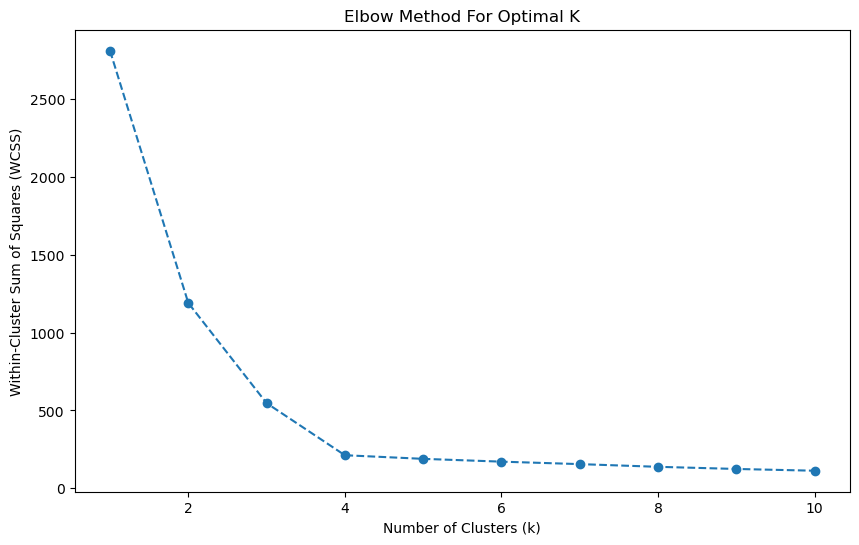

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Re-generate the same synthetic data for consistency
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

WCSS = []
max_k = 10  # Let's test k from 1 to 10

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, random_state=0, n_init=10)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)  # inertia_ is the WCSS

# Plotting the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_k + 1), WCSS, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')

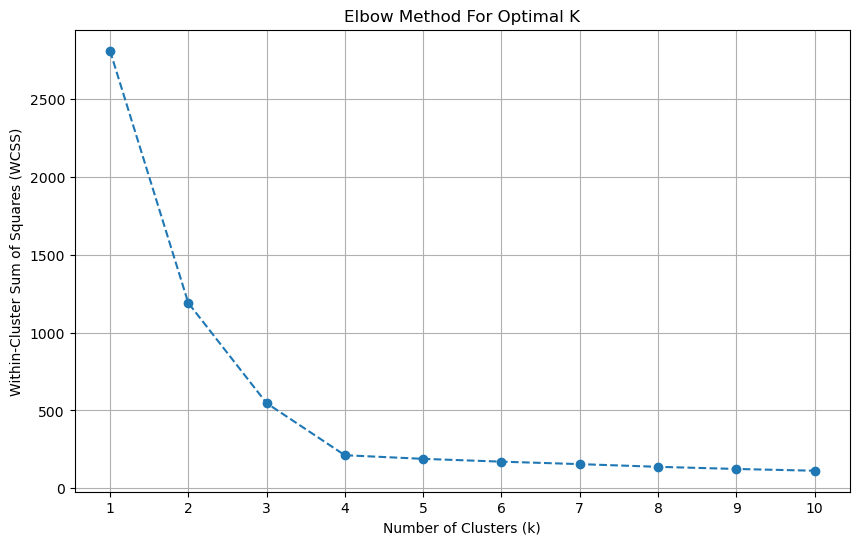

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Re-generate the same synthetic data for consistency
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

WCSS = []
max_k = 10  # Let's test k from 1 to 10

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, random_state=0, n_init=10)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)  # inertia_ is the WCSS

# Plotting the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_k + 1), WCSS, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(range(1, max_k + 1))
plt.grid(True)
plt.show()

## Task 3: Exploring Agglomerative Hierarchical Clustering
### Description: Agglomerative Hierarchical Clustering is a bottom-up clustering technique used to group similar data points into clusters. This task will guide you through creating a dendrogram using the Ward linkage method to visualize the hierarchical relationships between data points. You will then apply Agglomerative Clustering to divide the given dataset into two clusters and visualize the results using a scatter plot.

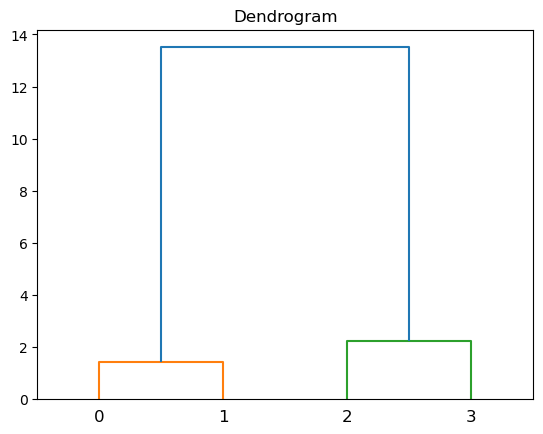

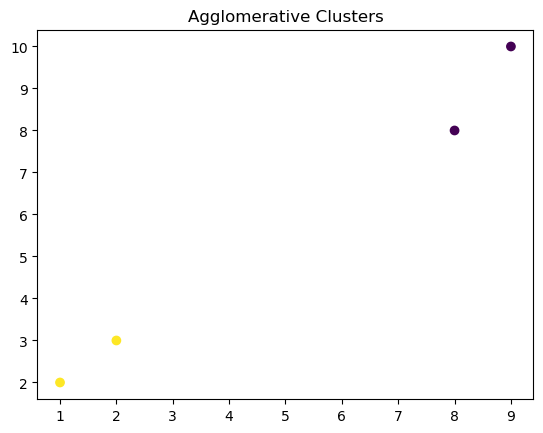

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

X = [[1, 2], [2, 3], [8, 8], [9, 10]]

# Diagram 1: Dendrogram
linked = linkage(X, method="ward")
plt.figure()
dendrogram(linked)
plt.title("Dendrogram")
plt.show()

# Divide into 2 clusters
model = AgglomerativeClustering(n_clusters=2, linkage="ward")
labels = model.fit_predict(X)

# Diagram 2: Clusters
plt.figure()
plt.scatter([p[0] for p in X], [p[1] for p in X], c=labels)
plt.title("Agglomerative Clusters")
plt.show()